# Markov Models

In this lab we will use Markov models to study human languages.

## Data Preparation

Before we can actually think about mathematical modeling, we need to gather some sample data to work on. For this lab, we will be retrieving text from the website of [Project Gutenberg](https://www.gutenberg.org/).

Go to that project website and find the page for "The Hound of the Baskervilles" novel. In particular, load the simple text form of the book.

Now define a Python variable `novel` and assign to it the first few paragraphs of Chapter 1.

<div class="alert alert-info">
In Python there is a specific syntax to define multi-line strings. If you use such syntax, you can simply copy and paste the novel text from the Project Gutenberg website.
</div>

The text that you have just copied it's too complex for our purposes. It contains not only words, but also punctuation marks and empty lines.

At the and of our data preparation we want a string containing only words separated by single spaces. Say we start from:

```
“I have, at least, a well-polished, silver-plated coffee-pot in front of
me,” said he.
```

Our final output should be:

```
i have at least a well polished silver pated coffee pot in front of me said he
```

Your first task is therefore to simplify the data, performing the following steps (not necessarily in this order):
* remove the distinction from upper and lower case, for instance converting everything to lower case;
* remove all characters that are not letters or spaces;
* remove empty lines and redundant spaces (words must be separated by a **single** space).

In [19]:
novel = """Mr. Sherlock Holmes, who was usually very late in the mornings,
      save upon those not infrequent occasions when he was up all
      night, was seated at the breakfast table. I stood upon the
      hearth-rug and picked up the stick which our visitor had left
      behind him the night before. It was a fine, thick piece of wood,
      bulbous-headed, of the sort which is known as a “Penang lawyer.”
      Just under the head was a broad silver band nearly an inch
      across. “To James Mortimer, M.R.C.S., from his friends of the
      C.C.H.,” was engraved upon it, with the date “1884.” It was just
      such a stick as the old-fashioned family practitioner used to
      carry—dignified, solid, and reassuring.

      “Well, Watson, what do you make of it?”

      Holmes was sitting with his back to me, and I had given him no
      sign of my occupation.

      “How did you know what I was doing? I believe you have eyes in
      the back of your head.”

      “I have, at least, a well-polished, silver-plated coffee-pot in
      front of me,” said he. “But, tell me, Watson, what do you make of
      our visitor’s stick? Since we have been so unfortunate as to miss
      him and have no notion of his errand, this accidental souvenir
      becomes of importance. Let me hear you reconstruct the man by an
      examination of it.”

      “I think,” said I, following as far as I could the methods of my
      companion, “that Dr. Mortimer is a successful, elderly medical
      man, well-esteemed since those who know him give him this mark of
      their appreciation.”

      “Good!” said Holmes. “Excellent!”

      “I think also that the probability is in favour of his being a
      country practitioner who does a great deal of his visiting on
      foot.”

      “Why so?”

      “Because this stick, though originally a very handsome one has
      been so knocked about that I can hardly imagine a town
      practitioner carrying it. The thick-iron ferrule is worn down, so
      it is evident that he has done a great amount of walking with
      it.”"""

Remember that Python strings behave like containers. They are collections of single characters that you can iterate upon using `for` loops or list comprehensions.

You may find the following two functions useful for converting strings into actual lists and vice-versa.

In [20]:
def string2list(s):
    return list(s)

In [21]:
def list2string(l):
    return ''.join(l)  # join all characters together

And the following two functions for converting strings into list of words and vice-versa.

In [22]:
def string2words(s):
    return s.split(' ')  # split on spaces

In [23]:
def words2string(ws):
    return ' '.join(ws)  # join words with a spaces between each pair

Now implement the transformations described above.

In [24]:
#Takes just characters, spaces and numbers and returns a lowecase string with no symbols.
justalpha = []
for char in novel:
    if char.isalpha() == True or char == " ":
        justalpha.append(char)
novel = list2string(justalpha)
novel= novel.lower()

In [25]:
#Eliminates all of the spaces
nospaces=[]
for i in string2words(novel):
    if i != '':
        nospaces.append(i)
print(nospaces)

['mr', 'sherlock', 'holmes', 'who', 'was', 'usually', 'very', 'late', 'in', 'the', 'mornings', 'save', 'upon', 'those', 'not', 'infrequent', 'occasions', 'when', 'he', 'was', 'up', 'all', 'night', 'was', 'seated', 'at', 'the', 'breakfast', 'table', 'i', 'stood', 'upon', 'the', 'hearthrug', 'and', 'picked', 'up', 'the', 'stick', 'which', 'our', 'visitor', 'had', 'left', 'behind', 'him', 'the', 'night', 'before', 'it', 'was', 'a', 'fine', 'thick', 'piece', 'of', 'wood', 'bulbousheaded', 'of', 'the', 'sort', 'which', 'is', 'known', 'as', 'a', 'penang', 'lawyer', 'just', 'under', 'the', 'head', 'was', 'a', 'broad', 'silver', 'band', 'nearly', 'an', 'inch', 'across', 'to', 'james', 'mortimer', 'mrcs', 'from', 'his', 'friends', 'of', 'the', 'cch', 'was', 'engraved', 'upon', 'it', 'with', 'the', 'date', 'it', 'was', 'just', 'such', 'a', 'stick', 'as', 'the', 'oldfashioned', 'family', 'practitioner', 'used', 'to', 'carrydignified', 'solid', 'and', 'reassuring', 'well', 'watson', 'what', 'do', 

In [26]:
#Reattatches the words with a space in between
novel_clean = words2string(nospaces)
print(novel_clean)

mr sherlock holmes who was usually very late in the mornings save upon those not infrequent occasions when he was up all night was seated at the breakfast table i stood upon the hearthrug and picked up the stick which our visitor had left behind him the night before it was a fine thick piece of wood bulbousheaded of the sort which is known as a penang lawyer just under the head was a broad silver band nearly an inch across to james mortimer mrcs from his friends of the cch was engraved upon it with the date it was just such a stick as the oldfashioned family practitioner used to carrydignified solid and reassuring well watson what do you make of it holmes was sitting with his back to me and i had given him no sign of my occupation how did you know what i was doing i believe you have eyes in the back of your head i have at least a wellpolished silverplated coffeepot in front of me said he but tell me watson what do you make of our visitors stick since we have been so unfortunate as to m

Now that we have cleaned up the text we will be using, there is one more conversion we have to make before we think abount the mathematical modeling.

Each character in our string will be represented as a different _state_ of a Markov model. As states are usually labeled with integer numbers (1, 2 ...), we need a way to convert each letter into an integer.

Start by defining a function which takes the list of all possible characters (which you have used above for the cleanup) and assign to each a different number (starting from 0). For instance, one possible pairing would be:

```
a -> 0
b -> 1
c -> 2
...
```

In [27]:
#This creates a dictionary that relates each letter to an individual numerical value
def letters2int(seq):
    d = {}
    c = 0
    for i in seq:
        if i not in d:
            d[i] = c
            c+=1
    return(d)
letters2int(novel_clean)

{'m': 0,
 'r': 1,
 ' ': 2,
 's': 3,
 'h': 4,
 'e': 5,
 'l': 6,
 'o': 7,
 'c': 8,
 'k': 9,
 'w': 10,
 'a': 11,
 'u': 12,
 'y': 13,
 'v': 14,
 't': 15,
 'i': 16,
 'n': 17,
 'g': 18,
 'p': 19,
 'f': 20,
 'q': 21,
 'd': 22,
 'b': 23,
 'j': 24,
 'x': 25}

Now write a second function that:
* converts the cleaned-up text into a list of characters;
* replaces each character with the correct number.

Using the mapping defined above, the string
```
acca
```

would become
```python
[0, 2, 2, 0]
```

In [28]:
import string
keys = letters2int(string.ascii_lowercase)
keys.update({" " : 26})

In [29]:
def string2ints(s):
    keys = letters2int(string.ascii_lowercase + " ")
    return [keys[c] for c in s]

In [30]:
integers = (string2ints(novel_clean))
print(integers)

[12, 17, 26, 18, 7, 4, 17, 11, 14, 2, 10, 26, 7, 14, 11, 12, 4, 18, 26, 22, 7, 14, 26, 22, 0, 18, 26, 20, 18, 20, 0, 11, 11, 24, 26, 21, 4, 17, 24, 26, 11, 0, 19, 4, 26, 8, 13, 26, 19, 7, 4, 26, 12, 14, 17, 13, 8, 13, 6, 18, 26, 18, 0, 21, 4, 26, 20, 15, 14, 13, 26, 19, 7, 14, 18, 4, 26, 13, 14, 19, 26, 8, 13, 5, 17, 4, 16, 20, 4, 13, 19, 26, 14, 2, 2, 0, 18, 8, 14, 13, 18, 26, 22, 7, 4, 13, 26, 7, 4, 26, 22, 0, 18, 26, 20, 15, 26, 0, 11, 11, 26, 13, 8, 6, 7, 19, 26, 22, 0, 18, 26, 18, 4, 0, 19, 4, 3, 26, 0, 19, 26, 19, 7, 4, 26, 1, 17, 4, 0, 10, 5, 0, 18, 19, 26, 19, 0, 1, 11, 4, 26, 8, 26, 18, 19, 14, 14, 3, 26, 20, 15, 14, 13, 26, 19, 7, 4, 26, 7, 4, 0, 17, 19, 7, 17, 20, 6, 26, 0, 13, 3, 26, 15, 8, 2, 10, 4, 3, 26, 20, 15, 26, 19, 7, 4, 26, 18, 19, 8, 2, 10, 26, 22, 7, 8, 2, 7, 26, 14, 20, 17, 26, 21, 8, 18, 8, 19, 14, 17, 26, 7, 0, 3, 26, 11, 4, 5, 19, 26, 1, 4, 7, 8, 13, 3, 26, 7, 8, 12, 26, 19, 7, 4, 26, 13, 8, 6, 7, 19, 26, 1, 4, 5, 14, 17, 4, 26, 8, 19, 26, 22, 0, 18, 26, 0, 2

## Markov Model, order 1

Here we are interested in estimating an order 1 Markov model representing our text.

In practice, we need to build a matrix capturing all the transition probabilities between pairs of characters.

The actual workflow will be we following:
* build a numpy matrix representing transitions between characters of the appropriate size;
* the matrix should be initially filled with zeroes;
* for each pair of characters (say 'a' and 'b') count how many times the pair 'ab' appears in the text and store it in the matrix;
* transform the frequency matrix into a proability matrix.

Implement in Python code the above steps. You may want to start doing one step at a time, interacting with the notebook. Later you should gather all the code into a single function like the following:

```python
def estimate_markov_1(s):  # s is the input text
    # do stuff
    return m  # m is the computed probability matrix
```

In [31]:
import numpy as np

In [56]:
def estimate_markov_1(s):  # s in the input text
    
    def permutations(s):
        t=string2ints(s)
        l=[]
        for i in range(len(t)-1):
            A = t[i]
            B = t[i+1]
            l.append([A,B])
        
        return(l)
    
    ##############
    
    def counter(l):
        
        import string
        keys = letters2int(string.ascii_lowercase)
        keys.update({" " : 26})
        
        z = np.zeros((len(keys),len(keys)))
        for element in l:
            f = element[0]
            c = element[1]
            z[f,c] += 1
        return z

    #############

    def probmatrix(z):
        row_sums = z.sum(axis=1, keepdims=True)
    

        row_sums[row_sums == 0] = 1 #this fornces to not be zero
        
        return z / row_sums

    l = permutations(s) #this creates the permutation matrix with all possible combinations of states
    
    z = counter(l) #and this creates a matrix that counts all the incidences of the states
    
    m = probmatrix(z) #Calculate the probability of each incidence and account for possible nan's
    
    return m  # m is the computed probability matrix

In [57]:
print(novel_clean)

mr sherlock holmes who was usually very late in the mornings save upon those not infrequent occasions when he was up all night was seated at the breakfast table i stood upon the hearthrug and picked up the stick which our visitor had left behind him the night before it was a fine thick piece of wood bulbousheaded of the sort which is known as a penang lawyer just under the head was a broad silver band nearly an inch across to james mortimer mrcs from his friends of the cch was engraved upon it with the date it was just such a stick as the oldfashioned family practitioner used to carrydignified solid and reassuring well watson what do you make of it holmes was sitting with his back to me and i had given him no sign of my occupation how did you know what i was doing i believe you have eyes in the back of your head i have at least a wellpolished silverplated coffeepot in front of me said he but tell me watson what do you make of our visitors stick since we have been so unfortunate as to m

In [58]:
mm1 = estimate_markov_1(novel_clean)
print(mm1)

[[0.         0.02479339 0.05785124 0.04958678 0.         0.
  0.00826446 0.         0.02479339 0.         0.02479339 0.0661157
  0.03305785 0.12396694 0.         0.00826446 0.         0.0661157
  0.17355372 0.17355372 0.00826446 0.05785124 0.00826446 0.
  0.         0.         0.09090909]
 [0.19047619 0.         0.         0.         0.38095238 0.
  0.         0.         0.04761905 0.         0.         0.04761905
  0.         0.         0.0952381  0.         0.         0.0952381
  0.         0.         0.0952381  0.         0.         0.
  0.04761905 0.         0.        ]
 [0.125      0.         0.10416667 0.         0.125      0.
  0.         0.10416667 0.04166667 0.         0.22916667 0.
  0.         0.         0.125      0.         0.         0.02083333
  0.02083333 0.08333333 0.02083333 0.         0.         0.
  0.         0.         0.        ]
 [0.01851852 0.         0.         0.         0.11111111 0.01851852
  0.         0.         0.05555556 0.         0.         0.01851852

## Data Probability given a Model

We have now build a model for our text. Unfortunately, it is quite difficult to check whether our computation is correct staring at the model matrix. Since we are nonetheless interested in verifying the correctness of our algorithm, we will adopt a different strategy.

We have estimated our model from a specific piece of text. In statistical terms, we have computed:

$$ P(\theta | D ) $$

where $\theta$ represents the parameters of the model and $D$ the input data.

In this particular case it is quite easy to compute the inverse, that is:

$$ L(D | \theta) $$

the likelihood of a piece of text under the assumption that it was generated by the Markov model.

In computational terms we need to:
* scan the original text;
* for each pair of characters look up the corresponding probability in the model;
* since we assume each pair is an independent event, we can obtain the total probability for the text by multiplying all the intermediate values.

The last step is possible due to the well known probability relation for **independent** events:

$$ P(A,B) = P(A) P(B) $$

There is one last detail we should take care of. The probabilities in our model are going to be quite small. Say $P(A)=0.02$ and $P(B)=0.03$. When we multiply them together, the result is even smaller: $P(A,B) = 0.0006$.

In the long run, this is going to cause numerical problems. The computer is only precise to a certain level; if we get very small values they became essentially indistinguishable from zero.

Luckily, we can use a trick to sidestep this issue: take the logarithm of the probability. By the property of the logarithm, products turn into sums:

$$ \log(\prod_i p_i) = \sum_i \log(p_i) $$

Instead of computing the likelihood directly, we will therefore compute the log-likelihood.

OK, we are now ready to write some code. Implement a function doing the following:
* iterate over all successive pairs in a text;
* look up the corresponding probability in the model;
* take its logarithm;
* return the sum of all logarithms.

<div class="alert alert-warning">
What happens if you have a transition probability of zero? What is its logarithm?
Can you figure a meaningful way to solve this issue?
</div>

In [38]:
def loglik(ints, m):
    log_likelihood = 0.0

    for i in range(len(ints) - 1):
        a = ints[i]
        b = ints[i + 1]

        p = m[a, b]

        if p == 0:
            log_likelihood += -1000
        else:
            log_likelihood += np.log(p)

    return log_likelihood

In [39]:
loglik(string2ints(novel_clean), mm1)

np.float64(-3860.588669695982)

The value of the log-likelihood is again not particularly informative on its own. We need to compute the log-likelihood on a different text to establish a baseline for comparison.

Let's build a random sequence of characters of the same length of the novel fragment we have used. To this end we will use a function of the `numpy` package.

In [41]:
novel_random = np.random.randint(0, 27, len(string2ints(novel_clean)))

Now compute the log-likelihood on this new text (you can reuse the function!) and compare it with the previous result.

The Markov model we have generated "explains" better the first (novel) text or the second (random) one?

In [43]:
loglik(novel_random, mm1) #This will indicate a 'worse' value meaning that our more 'ordered' and not random novel will have a 'better' log likelik

np.float64(-1157770.7248382268)

In [ ]:
## Language Detection

In the last section we learned how to measure the likelihood that a given piece of text derives from a given Markov model. We can now put this knowledge to some practical use by implementing a language classificator.

The idea is to build a software that can automatically detect the language (such as Italian or English) of a string provided by the user.

To do that, we first need to train the software with some samples of each language. For English, we already have our novel.

In [44]:
english_sample = novel_clean

Now go to the Project Gutenberg website and get a sample of French and Italian. Define two more variables, `french_sample` and `italian_sample`, cleaning each text sample in the same way you've done with the english text.

In [64]:
def clean_sample(s):
    s = s.lower()

    chars = []
    for c in string2list(s):

        # I need to account for all of the special characters that are in other languages
        if c in "àáâäãå":
            c = "a"
        elif c in "èéêë":
            c = "e"
        elif c in "ìíîï":
            c = "i"
        elif c in "òóôöõœ":
            c = "o"
        elif c in "ùúûü":
            c = "u"
        elif c == "ç":
            c = "c"

        if c.isalpha() or c == " ":
            chars.append(c)

    s = list2string(chars)

    words = []
    for w in string2words(s):
        if w != "":
            words.append(w)

    return words2string(words)

<div class="alert alert-info">
Compare the cleaned-up version of the french text with the original. Do you notice any significant difference?
<br><br>
When you've identified it, contact one of the instructors.
</div>

In [65]:
french_sample = clean_sample("""LE GUN-CLUB 

Pendant la guerre fédérale des États-Unis, un nouveau club très influent s'établit dans la ville de Baltimore, en plein Maryland. On sait avec quelle énergie l'instinct militaire se développa chez ce peuple d'armateurs, de marchands et de mécaniciens. De simples négociants enjambèrent leur comptoir pour s'improviser capitaines, colonels, généraux, sans avoir passé par les écoles d'application de West-Point [École militaire des États-Unis.]; ils égalèrent bientôt dans «L'art de la guerre» leurs collègues du vieux continent, et comme eux ils remportèrent des victoires à force de prodiguer les boulets, les millions et les hommes.

Mais en quoi les Américains surpassèrent singulièrement les Européens, ce fut dans la science de la balistique. Non que leurs armes atteignissent un plus haut degré de perfection, mais elles offrirent des dimensions inusitées, et eurent par conséquent des portées inconnues jusqu'alors. En fait de tirs rasants, plongeants ou de plein fouet, de feux d'écharpe, d'enfilade ou de revers, les Anglais, les Français, les Prussiens, n'ont plus rien à apprendre; mais leurs canons, leurs obusiers, leurs mortiers ne sont que des pistolets de poche auprès des formidables engins de l'artillerie américaine.

Ceci ne doit étonner personne. Les Yankees, ces premiers mécaniciens du monde, sont ingénieurs, comme les Italiens sont musiciens et les Allemands métaphysiciens,—de naissance. Rien de plus naturel, dès lors, que de les voir apporter dans la science de la balistique leur audacieuse ingéniosité. De là ces canons gigantesques, beaucoup moins utiles que les machines à coudre, mais aussi étonnants et encore plus admirés. On connaît en ce genre les merveilles de Parrott, de Dahlgreen, de Rodman. Les Armstrong, les Pallisser et les Treuille de Beaulieu n'eurent plus qu'à s'incliner devant leurs rivaux d'outre-mer.

Donc, pendant cette terrible lutte des Nordistes et des Sudistes, les artilleurs tinrent le haut du pavé; les journaux de l'Union célébraient leurs inventions avec enthousiasme, et il n'était si mince marchand, si naïf «booby» [Badaud.], qui ne se cassât jour et nuit la tête à calculer des trajectoires insensées.

Or, quand un Américain a une idée, il cherche un second Américain qui la partage. Sont-ils trois, ils élisent un président et deux secrétaires. Quatre, ils nomment un archiviste, et le bureau fonctionne. Cinq, ils se convoquent en assemblée générale, et le club est constitué. Ainsi arriva-t-il à Baltimore. Le premier qui inventa un nouveau canon s'associa avec le premier qui le fondit et le premier qui le fora. Tel fut le noyau du Gun-Club [Littéralement «Club-Canon».]. Un mois après sa formation, il comptait dix-huit cent trente-trois membres effectifs et trente mille cinq cent soixante-quinze membres correspondants.

Une condition sine qua non était imposée à toute personne qui voulait entrer dans l'association, la condition d'avoir imaginé ou, tout au moins, perfectionné un canon; à défaut de canon, une arme à feu quelconque. Mais, pour tout dire, les inventeurs de revolvers à quinze coups, de carabines pivotantes ou de sabres-pistolets ne jouissaient pas d'une grande considération. Les artilleurs les primaient en toute circonstance.

«L'estime qu'ils obtiennent, dit un jour un des plus savants orateurs du Gun-Club, est proportionnelle «aux masses» de leur canon, et «en raison directe du carré des distances» atteintes par leurs projectiles!

Un peu plus, c'était la loi de Newton sur la gravitation universelle transportée dans l'ordre moral.

Le Gun-Club fondé, on se figure aisément ce que produisit en ce genre le génie inventif des Américains. Les engins de guerre prirent des proportions colossales, et les projectiles allèrent, au-delà des limites permises, couper en deux les promeneurs inoffensifs. Toutes ces inventions laissèrent loin derrière elles les timides instruments de l'artillerie européenne. Qu'on en juge par les chiffres suivants.

Jadis, «au bon temps», un boulet de trente-six, à une distance de trois cents pieds, traversait trente-six chevaux pris de flanc et soixante-huit hommes. C'était l'enfance de l'art. Depuis lors, les projectiles ont fait du chemin. Le canon Rodman, qui portait à sept milles [Le mille vaut 1609 mètres 31 centimètres. Cela fait donc près de trois lieues.] un boulet pesant une demi-tonne [Cinq cents kilogrammes.] aurait facilement renversé cent cinquante chevaux et trois cents hommes. Il fut même question au Gun-Club d'en faire une épreuve solennelle. Mais, si les chevaux consentirent à tenter l'expérience, les hommes firent malheureusement défaut.

Quoi qu'il en soit, l'effet de ces canons était très meurtrier, et à chaque décharge les combattants tombaient comme des épis sous la faux. Que signifiaient, auprès de tels projectiles, ce fameux boulet qui, à Coutras, en 1587, mit vingt-cinq hommes hors de combat, et cet autre qui, à Zorndoff, en 1758, tua quarante fantassins, et, en 1742, ce canon autrichien de Kesselsdorf, dont chaque coup jetait soixante-dix ennemis par terre? Qu'étaient ces feux surprenants d'Iéna ou d'Austerlitz qui décidaient du sort de la bataille? On en avait vu bien d'autres pendant la guerre fédérale! Au combat de Gettysburg, un projectile conique lancé par un canon rayé atteignit cent soixante-treize confédérés; et, au passage du Potomac, un boulet Rodman envoya deux cent quinze Sudistes dans un monde évidemment meilleur. Il faut mentionner également un mortier formidable inventé par J.-T. Maston, membre distingué et secrétaire perpétuel du Gun-Club, dont le résultat fut bien autrement meurtrier, puisque, à son coup d'essai, il tua trois cent trente-sept personnes,—en éclatant, il est vrai!

Qu'ajouter à ces nombres si éloquents par eux-mêmes? Rien. Aussi admettra-t-on sans conteste le calcul suivant, obtenu par le statisticien Pitcairn: en divisant le nombre des victimes tombées sous les boulets par celui des membres du Gun-Club, il trouva que chacun de ceux-ci avait tué pour son compte une «moyenne» de deux mille trois cent soixante-quinze hommes et une fraction.

A considérer un pareil chiffre, il est évident que l'unique préoccupation de cette société savante fut la destruction de l'humanité dans un but philanthropique, et le perfectionnement des armes de guerre, considérées comme instruments de civilisation.

C'était une réunion d'Anges Exterminateurs, au demeurant les meilleurs fils du monde.

Il faut ajouter que ces Yankees, braves à toute épreuve, ne s'en tinrent pas seulement aux formules et qu'ils payèrent de leur personne. On comptait parmi eux des officiers de tout grade, lieutenants ou généraux, des militaires de tout âge, ceux qui débutaient dans la carrière des armes et ceux qui vieillissaient sur leur affût. Beaucoup restèrent sur le champ de bataille dont les noms figuraient au livre d'honneur du Gun-Club, et de ceux qui revinrent la plupart portaient les marques de leur indiscutable intrépidité. Béquilles, jambes de bois, bras articulés, mains à crochets, mâchoires en caoutchouc, crânes en argent, nez en platine, rien ne manquait à la collection, et le susdit Pitcairn calcula également que, dans le Gun-Club, il n'y avait pas tout à fait un bras pour quatre personnes, et seulement deux jambes pour six.

Mais ces vaillants artilleurs n'y regardaient pas de si près, et ils se sentaient fiers à bon droit, quand le bulletin d'une bataille relevait un nombre de victimes décuple de la quantité de projectiles dépensés.

Un jour, pourtant, triste et lamentable jour, la paix fut signée par les survivants de la guerre, les détonations cessèrent peu à peu, les mortiers se turent, les obusiers muselés pour longtemps et les canons, la tête basse, rentrèrent aux arsenaux, les boulets s'empilèrent dans les parcs, les souvenirs sanglants s'effacèrent, les cotonniers poussèrent magnifiquement sur les champs largement engraissés, les vêtements de deuil achevèrent de s'user avec les douleurs, et le Gun-Club demeura plongé dans un désœuvrement profond.

Certains piocheurs, des travailleurs acharnés, se livraient bien encore à des calculs de balistique; ils rêvaient toujours de bombes gigantesques et d'obus incomparables. Mais, sans la pratique, pourquoi ces vaines théories? Aussi les salles devenaient désertes, les domestiques dormaient dans les antichambres, les journaux moisissaient sur les tables, les coins obscurs retentissaient de ronflements tristes, et les membres du Gun-Club, jadis si bruyants, maintenant réduits au silence par une paix désastreuse, s'endormaient dans les rêveries de l'artillerie platonique!")""")

In [66]:
italian_sample = clean_sample("""Inferno • Canto I

Nel mezzo del cammin di nostra vita
mi ritrovai per una selva oscura,
ché la diritta via era smarrita.

Ahi quanto a dir qual era è cosa dura
esta selva selvaggia e aspra e forte
che nel pensier rinova la paura!

Tant’ è amara che poco è più morte;
ma per trattar del ben ch’i’ vi trovai,
dirò de l’altre cose ch’i’ v’ho scorte.

Io non so ben ridir com’ i’ v’intrai,
tant’ era pien di sonno a quel punto
che la verace via abbandonai.

Ma poi ch’i’ fui al piè d’un colle giunto,
là dove terminava quella valle
che m’avea di paura il cor compunto,

guardai in alto e vidi le sue spalle
vestite già de’ raggi del pianeta
che mena dritto altrui per ogne calle.

Allor fu la paura un poco queta,
che nel lago del cor m’era durata
la notte ch’i’ passai con tanta pieta.

E come quei che con lena affannata,
uscito fuor del pelago a la riva,
si volge a l’acqua perigliosa e guata,

così l’animo mio, ch’ancor fuggiva,
si volse a retro a rimirar lo passo
che non lasciò già mai persona viva.

Poi ch’èi posato un poco il corpo lasso,
ripresi via per la piaggia diserta,
sì che ’l piè fermo sempre era ’l più basso.

Ed ecco, quasi al cominciar de l’erta,
una lonza leggera e presta molto,
che di pel macolato era coverta;

e non mi si partia dinanzi al volto,
anzi ’mpediva tanto il mio cammino,
ch’i’ fui per ritornar più volte vòlto.

Temp’ era dal principio del mattino,
e ’l sol montava ’n sù con quelle stelle
ch’eran con lui quando l’amor divino

mosse di prima quelle cose belle;
sì ch’a bene sperar m’era cagione
di quella fiera a la gaetta pelle

l’ora del tempo e la dolce stagione;
ma non sì che paura non mi desse
la vista che m’apparve d’un leone.)""")

Now build three models, one for each sample.

In [67]:
english_model = estimate_markov_1(english_sample)
french_model = estimate_markov_1(french_sample)
italian_model = estimate_markov_1(italian_sample)

We are ready to build the classifier. Write a function that receives a single string input. It has to compute the log-likelihood of that string according to the different models and then pick the best one. The function return value should be the name of the guessed language.

In [68]:
def guess_language(s):

    #we need to clean our language sample first
    clean_guess = clean_sample(s)

    ints=string2ints(clean_guess)

    ll_en = loglik(ints, english_model)
    ll_fr = loglik(ints, french_model)
    ll_it = loglik(ints, italian_model)

    scores = {
        "english": ll_en,
        "french": ll_fr,
        "italian": ll_it
    }

    guess = max(scores, key = scores.get)

    return guess

In [69]:
guess_language("ecco un messaggio scritto in italiano")

'italian'

In [74]:
guess_language("a sample message written in plain english gets a good classification. I hope that adding this text can help with classification")

'french'

In [73]:
print(guess_language('''
Allons enfants de la Patrie
Le jour de gloire est arrivé!
Contre nous de la tyrannie
'''))
print(guess_language('''
No man is an island,
Entire of itself,
Every man is a piece of the continent,
A part of the main.
If a clod be washed away by the sea,
Europe is the less.
As well as if a promontory were.
As well as if a manor of thy friend's
Or of thine own were:
Any man's death diminishes me,
Because I am involved in mankind,
And therefore never send to know for whom the bell tolls;
It tolls for thee.
'''))

french
english


## Performance Evaluation

<div class="alert alert-info">
This section is optional.
</div>

No classifier is perfect. Here we should put our function `guess_language` to the test and check in which conditions it works and in which it provides a wrong result.
There are two choices having a primary impact of performances: the size of the training dataset (text) and that of the message to be classified.

Here we will concentrate on the second, that is the message length. Write a function `extract_with_length` to extract a random selection out of a string, given a desired length.

For instance:

```python
extract_with_length('a simple message', 6)
```

should return, each time it is called, a (different) random substring of length 6.

Examples:

```python
>>> extract_with_length('a simple message', 6)
"a simp"
>>> extract_with_length('a simple message', 6)
"messag"
```

<div class="alert alert-info">
Import the ```random``` library. You can then use the ```random.randint``` function to generate random integer numbers. Use the Jupyter documentation to check how the function works.
</div>

In [80]:
import random

In [81]:
def extract_with_length(s, n):

    # this should help with the problem described that it accounts for a larger sub-string than the word's length
    # if this happens I could just return the complete word
    if n > len(s):
        return s
    start = random.randint(0, len(s) - n)
    return s[start:start + n]

What happens if I run the following code:

```python
extract_with_length('short', 20)
```

How can I avoid this problem, while improving the error message?

We can now implement a Monte Carlo simulation to evaluate the performance of our classifier with respect to the length of the input message.

* choose a length `l` (for instance, `l=10`) and extract 1000 random strings with `extract_with_length`;
* run `guess_language` on those strings and record whether the classifier was right or wrong;
* calculate the performance as the ratio between correct and total classifications;
* repeat the above procedure for all lengths `l` between 5 and 40.

Prepare a scatter plot displaying the value of `l` on the $x$ axis and the performance on the $y$ axis.

Do you see any trend? Can you explain it?


- Smaller fragment sizes tend to better approximate the language as it detects tell-tell combinations of letters.
- When bigger fragments are used it is possible that other language's combinations of letters are also present in our sample, so the model drops its performace.
- Shorter sentences then, have a better shot at being predicted.

In [90]:
import matplotlib.pylab as plt
%matplotlib inline

In [91]:
def performance_monte_carlo(template, expected_language):

    X = []
    Y = []

    for l in range(5, 41):

        correct = 0
        trials = 1000

        for _ in range(trials):

            sample = extract_with_length(template, l)
            guess = guess_language(sample)

            if guess == expected_language:
                correct += 1

        X.append(l)
        Y.append(correct / trials)

    plt.plot(X, Y)
    plt.xlabel('Fragment size (l)')
    plt.ylabel('Accuracy')
    plt.title('Accuracy measurment depending on random fragment size')
    print(guess_language(template))

french


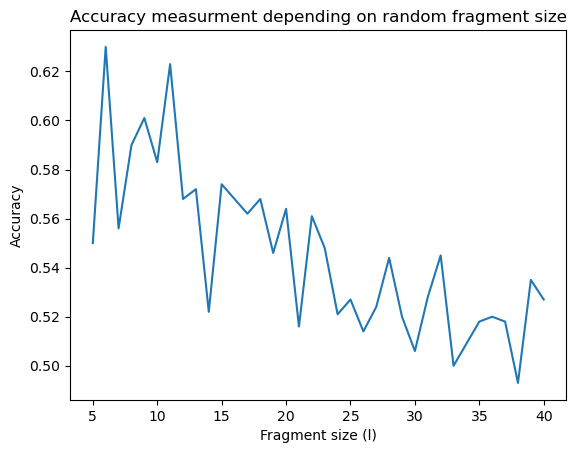

In [93]:
performance_monte_carlo(clean_sample('''
Va’, pensiero, sull'ali dorate;
va’, ti posa sui clivi, sui colli,
ove olezzano tepide e molli
l'aure dolci del suolo natal!

Del Giordano le rive saluta,
di Sionne le torri atterrate...
Oh, mia patria sì bella e perduta!
Oh, membranza sì cara e fatal!

Arpa d'or dei fatidici vati,
perché muta dal salice pendi?
Le memorie nel petto raccendi,
ci favella del tempo che fu!

O simile di Solima ai fati
traggi un suono di crudo lamento,
o t'ispiri il Signore un concento
che ne infonda al patire virtù!
'''), 'italian')

In [100]:
print(guess_language(clean_sample('this is a test')))
print(guess_language(clean_sample('questo e una prova')))
print(guess_language(clean_sample("Je te manque")))

english
italian
french


In [101]:
#As shown in the above examples, the model has easier times identifying shorter phrases.
# Even if the spelling is not the best (sorry) it is still a really good approximation

## Appendix A

In [ ]:
import unicodedata
def sa(s):
    return ''.join(c for c in unicodedata.normalize('NFD', s)
                   if unicodedata.category(c) != 'Mn')